# Anomaly Detection Analysis

This notebook analyzes the Isolation Forest anomaly detection stage and the calibrated risk scores.

**Important:** An anomaly is not automatically a confirmed insider threat.

The system produces an investigation priority score based on behavioral deviation and model output.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = os.path.abspath("..")
PROCESSED_DIR = os.path.join(BASE_DIR, "dataset", "processed")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

path = os.path.join(PROCESSED_DIR, "Risk_Scored_Dataset.csv")
df = pd.read_csv(path)

df["day"] = pd.to_datetime(df["day"])

print("Records:", len(df))

Records: 334905


In [2]:
print("Risk score statistics:")
display(
    df["calibrated_risk_score"]
    .describe()
    .to_frame("calibrated_risk_score")
)

print("\nRisk level distribution:")
display(
    df["risk_level"]
    .value_counts()
    .to_frame("user_days")
)

Risk score statistics:


,calibrated_risk_score
count,334905.000000
mean,50.000149
std,26.743664
min,6.555665
25%,25.897254
50%,47.731327
75%,72.276228
max,99.999791



Risk level distribution:


,user_days
risk_level,
Medium,83744
Critical,83727
High,83721
Low,83713


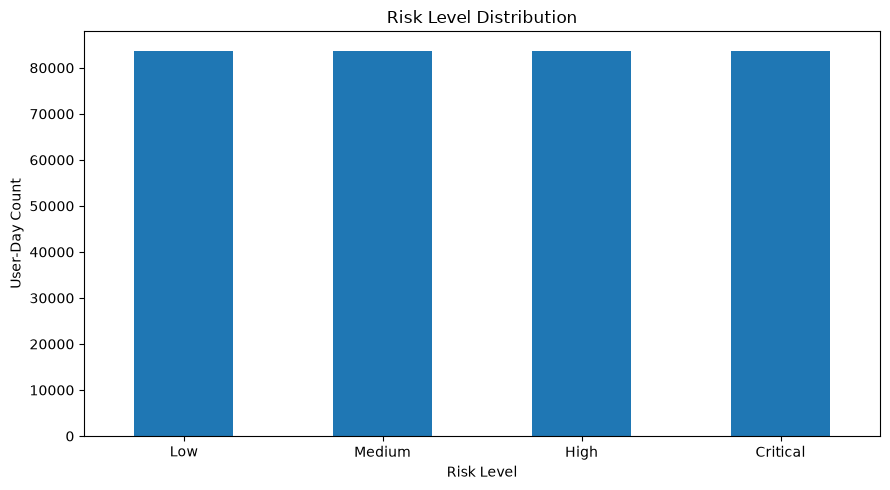

In [3]:
plt.figure(figsize=(9, 5))

risk_order = ["Low", "Medium", "High", "Critical"]
counts = df["risk_level"].value_counts().reindex(risk_order)

counts.plot(kind="bar")

plt.title("Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("User-Day Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
top_risk = df[
    [
        "user_id",
        "day",
        "Role",
        "calibrated_risk_score",
        "risk_level",
        "behavioral_deviation_score"
    ]
].sort_values(
    "calibrated_risk_score",
    ascending=False
)

display(top_risk.head(25))

,user_id,day,Role,calibrated_risk_score,risk_level,behavioral_deviation_score
0,JCS0873,2011-02-24,Technician,99.999791,Critical,8.027090
1,AGW0182,2011-04-13,Administrative Assistant,99.998567,Critical,5.037534
2,SJH0588,2011-02-24,Foreman,99.998507,Critical,5.386792
3,BAF0379,2011-05-11,Engineer,99.996477,Critical,4.132170
4,HAG0649,2011-02-23,Technician,99.996178,Critical,5.590661
5,AKS0283,2011-01-20,Security,99.994954,Critical,4.421380
6,AIB0797,2011-04-27,Administrative Staff,99.994625,Critical,5.532304
7,OYR0801,2011-05-13,Technician,99.994267,Critical,6.378392
8,AIB0797,2011-04-19,Administrative Staff,99.994103,Critical,4.087921
9,HCG0731,2011-04-21,Tradesman,99.994028,Critical,3.916494


In [5]:
role_risk = (
    df.groupby("Role")["calibrated_risk_score"]
    .agg(["mean", "median", "max", "count"])
    .sort_values("mean", ascending=False)
)

display(role_risk)

,mean,median,max,count
Role,,,,
IT Admin,90.202287,91.908840,99.982921,4238
Of Council,63.592484,61.450352,99.956316,2537
Loading Dock,58.758659,55.930936,99.956301,5127
Janitor,58.549115,58.033875,99.978158,9323
Project Manager,55.947656,57.638062,99.991863,9816
VP,50.738027,49.549723,99.813320,4140
Unknown,50.202756,51.893298,99.836849,691
Security,50.032360,50.043848,99.994954,14267
Tradesman,49.935248,45.751123,99.994028,47848


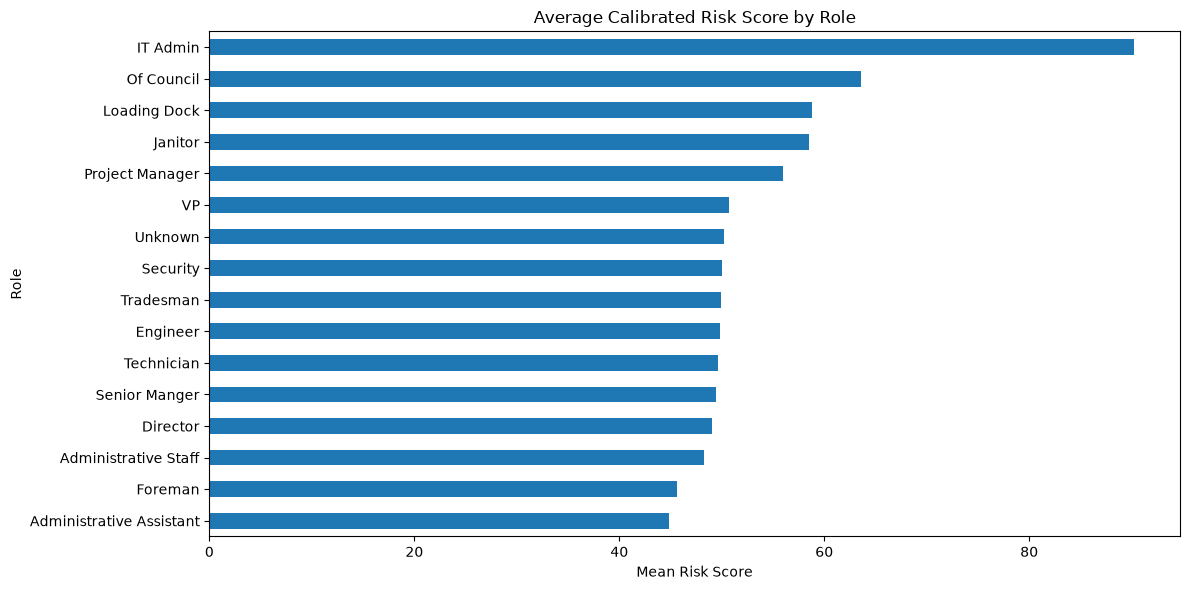

In [6]:
plt.figure(figsize=(12, 6))

role_risk["mean"].sort_values().plot(kind="barh")

plt.title("Average Calibrated Risk Score by Role")
plt.xlabel("Mean Risk Score")
plt.tight_layout()
plt.show()

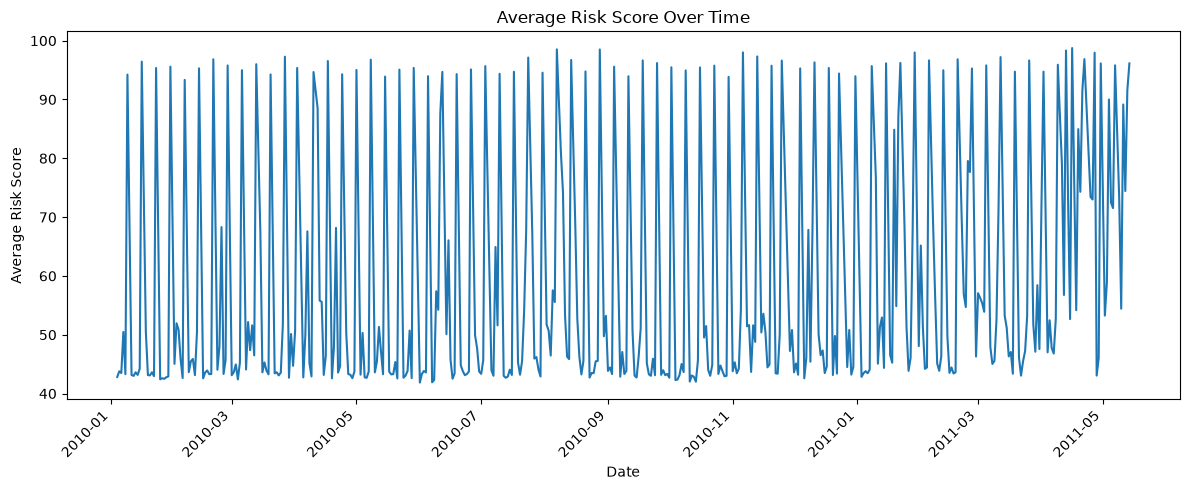

In [7]:
daily_risk = (
    df.groupby("day")["calibrated_risk_score"]
    .mean()
)

plt.figure(figsize=(12, 5))
daily_risk.plot()

plt.title("Average Risk Score Over Time")
plt.xlabel("Date")
plt.ylabel("Average Risk Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
print("Investigation-required user-days:")

investigation = df[df["investigation_required"] == 1]

print("Count:", len(investigation))
print(
    "Percentage:",
    round(len(investigation) / len(df) * 100, 2),
    "%"
)

Investigation-required user-days:
Count: 89826
Percentage: 26.82 %
